# 作业7

计算R语言自带的数据包states.x77（美国50个州在1977年的人口，收入，文盲率，预期寿命，谋杀率以及高中毕业率的数据）中各变量之间的相关关系，并找出具有显著性相关关系（设显著性水平为0.05）的两两变量。

cor()函数包：可以计算三种不同的相关系数如Pearson相关系数、Spearman相关系数、Kendall相关系数。而pcor()函数包则是计算偏相关系数。、

可视化：corrplot包。

## 准备工作

### 导入包

psych包是一个快捷计算变量之间相关系数和显著性检验的包

corrplot包是一个绘制相关性的包

In [1]:
library(psych)
library(corrplot)

Warning message:
"程辑包'psych'是用R版本4.2.3 来建造的"
Warning message:
"程辑包'corrplot'是用R版本4.2.3 来建造的"
corrplot 0.92 loaded



### 导入数据

In [2]:
states <- state.x77
head(states)

,Population,Income,Illiteracy,Life Exp,Murder,HS Grad,Frost,Area
Alabama,3615,3624,2.1,69.05,15.1,41.3,20,50708
Alaska,365,6315,1.5,69.31,11.3,66.7,152,566432
Arizona,2212,4530,1.8,70.55,7.8,58.1,15,113417
Arkansas,2110,3378,1.9,70.66,10.1,39.9,65,51945
California,21198,5114,1.1,71.71,10.3,62.6,20,156361
Colorado,2541,4884,0.7,72.06,6.8,63.9,166,103766


## 数据分析

### 相关分析和显著性检验

使用corr.test函数直接计算变量之间的相关系数同时进行显著性检验

In [3]:
corr.test(states,use="complete",method='pearson')

Call:corr.test(x = states, use = "complete", method = "pearson")
Correlation matrix 
           Population Income Illiteracy Life Exp Murder HS Grad Frost  Area
Population       1.00   0.21       0.11    -0.07   0.34   -0.10 -0.33  0.02
Income           0.21   1.00      -0.44     0.34  -0.23    0.62  0.23  0.36
Illiteracy       0.11  -0.44       1.00    -0.59   0.70   -0.66 -0.67  0.08
Life Exp        -0.07   0.34      -0.59     1.00  -0.78    0.58  0.26 -0.11
Murder           0.34  -0.23       0.70    -0.78   1.00   -0.49 -0.54  0.23
HS Grad         -0.10   0.62      -0.66     0.58  -0.49    1.00  0.37  0.33
Frost           -0.33   0.23      -0.67     0.26  -0.54    0.37  1.00  0.06
Area             0.02   0.36       0.08    -0.11   0.23    0.33  0.06  1.00
Sample Size 
[1] 50
Probability values (Entries above the diagonal are adjusted for multiple tests.) 
           Population Income Illiteracy Life Exp Murder HS Grad Frost Area
Population       0.00   1.00       1.00     1.00   0.2

### 绘图

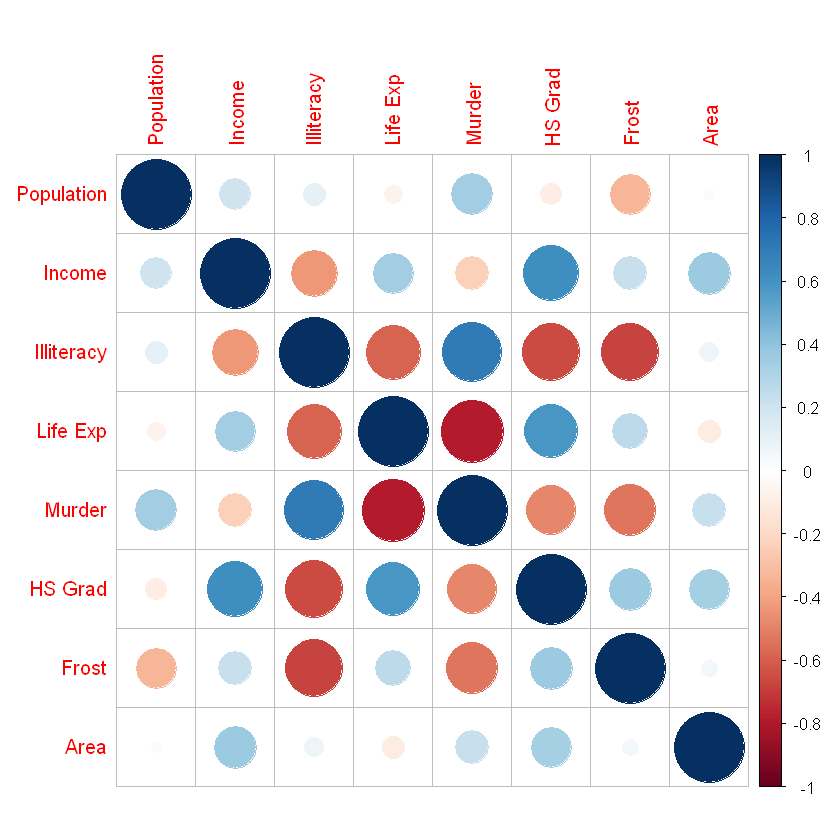

In [4]:
corrplot(cor(states))

### 协方差分析

In [5]:
cov(states,method='pearson')

,Population,Income,Illiteracy,Life Exp,Murder,HS Grad,Frost,Area
Population,19931683.7588,571229.7796,292.8679592,-4.078425e+02,5663.523714,-3551.509551,-77081.97265,8.587917e+06
Income,571229.7796,377573.3061,-163.7020408,2.806632e+02,-521.894286,3076.768980,7227.60408,1.904901e+07
Illiteracy,292.8680,-163.7020,0.3715306,-4.815122e-01,1.581776,-3.235469,-21.29000,4.018337e+03
Life Exp,-407.8425,280.6632,-0.4815122,1.802020e+00,-3.869480,6.312685,18.28678,-1.229410e+04
Murder,5663.5237,-521.8943,1.5817755,-3.869480e+00,13.627465,-14.549616,-103.40600,7.194043e+04
HS Grad,-3551.5096,3076.7690,-3.2354694,6.312685e+00,-14.549616,65.237894,153.99216,2.298732e+05
Frost,-77081.9727,7227.6041,-21.2900000,1.828678e+01,-103.406000,153.992163,2702.00857,2.627039e+05
Area,8587916.9494,19049013.7510,4018.3371429,-1.229410e+04,71940.429959,229873.192816,262703.89306,7.280748e+09


### 显著性检验

通过显著性检验可以发现：

收入和文盲率、谋杀率、高中毕业率具有显著相关关系

文盲率和收入、预期寿命、谋杀率、高中毕业率都有显著相关关系

谋杀率和人口、文盲率、预期寿命、高中毕业率有显著相关关系

高中毕业率与收入、文盲率、预期寿命、谋杀率都有显著相关关系

### 相关分析

收入和文盲率、谋杀率为负相关，和高中毕业率为正相关。这其中，收入和高中毕业率的相关性相对较大，和其他变量的相关性偏小。这说明收入会在一定程度上影响其他社会因素，但不是主要影响原因。收入和高中毕业率相关性大于和文盲率的关系可能是因为高中学业难度较大，相比“文盲”的标准更高，因此收入对家庭条件的影响有可能会影响到教育水平。

文盲率和收入、预期寿命、高中毕业率为负相关，和谋杀率为正相关，且相关系数普遍较大。这说明文盲率对于各种其他社会因素的影响较大，文盲率的提升会大幅度提高各种不良社会现象的出现，同时导致预期寿命减少。因此，控制文盲率应当成为控制不良社会现象的关键举措。

谋杀率和预期寿命、高中毕业率为负相关，和人口、文盲率为正相关。其中和预期寿命、高中毕业率的相关性不算太大，和文盲率的相关系数较大。这说明文盲率已经成为谋杀事件发生的主要因素，要想减少谋杀事件，必须降低社会文盲率，同时控制人口

高中毕业率和收入、预期寿命为正相关，与文盲率、谋杀率为负相关。但高中毕业率与各大因素的相关系数不如文盲率来得大。这个前面已经解释过，是因为文盲的程度比高中无法毕业更严重，是高中无法毕业的子集。这也可以从高中毕业率和文盲率的相关系数最大中体现出来。因此个人认为在实际数据分析的过程中，可以使用文盲率反向代替高中毕业率以体现更好的效果

由此可见，基本上各大正面因素与正面因素成正相关，负面因素与负面因素成负相关。与各大社会因素关系最显著、相关系数最大的是文盲率。美国政府应当尽可能降低文盲率来提升公民的生活水平同时降低恶性社会事件的发生概率